<p class="lead">You already know what a molecule is (Unit 1), that it is a labelled graph (Unit 2), how to serialise it as a string (Unit 3), how to turn it into a fixed vector of descriptors and fingerprints (Unit 5), and how to fit and <em>honestly</em> validate classical machine-learning models on those vectors (Units 12-14). This unit asks the next question: what changes when we let a neural network <em>learn its own representation</em> of a molecule instead of handing it one we designed? That is the whole idea of deep learning for molecules. The lecture sketches the landscape; this notebook makes the two central mechanisms concrete in NumPy — message passing on the molecular graph, and a character-level language model over SMILES — so that nothing stays a black box. We deliberately train nothing on a GPU and import no deep-learning framework: every mechanism here runs in seconds on a laptop, and the real tools are described and cited for when you need them.</p>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Name the four main ways a molecule is fed to a neural network — graph, SMILES string, image, and learned vector — and the network class each enables.</li>
<li>Explain what "message passing" on a molecular graph is, and trace one message-passing update on a four-atom molecule by hand, then reproduce it exactly in code.</li>
<li>Build a minimal message-passing neural network (MPNN) in NumPy whose learned read-out recovers a graph property that atom-composition alone cannot.</li>
<li>State what a <em>learned</em> fingerprint is and how it differs from the fixed ECFP/Morgan fingerprint of Unit 5.</li>
<li>Describe a character-level SMILES language model, build a Markov version in NumPy, and explain why it generates mostly invalid molecules and what fixes that.</li>
<li>State when deep learning is worth it over "fingerprints + a tree model", and name the production tools (chemprop, DeepChem) and what they do.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Run each cell as you reach it and read its output before the prose that follows. Green <strong>chemistry boxes</strong> define any chemical term on first use; most of this unit is informatics, so they are sparser than in earlier units. Everything is NumPy, pandas, scikit-learn, matplotlib and RDKit — the same stack as the rest of the course (in Colab: <code>!pip install rdkit</code>; the others are preinstalled). There is no <code>torch</code>, no <code>tensorflow</code>, no GPU: deep learning is taught here as a set of ideas you can compute by hand, and the heavy frameworks are pointed to, not run. This unit leans on the vocabulary of Units 2 (graph), 5 (fingerprints), 12-13 (QSAR/ML) and 14 (honest validation); keep them within reach.</p></div>

In [1]:
# Setup. In Google Colab, run once:  !pip install rdkit
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import rdkit
from rdkit import Chem
from rdkit.Chem import Draw, AllChem, rdMolDescriptors
rdkit.RDLogger.DisableLog("rdApp.*")        # silence RDKit parse warnings in this teaching notebook
rng = np.random.default_rng(0)              # one generator, seeded, for every random step below
np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
print("RDKit", rdkit.__version__, "| NumPy", np.__version__, "| no deep-learning framework is imported")

RDKit 2026.03.4 | NumPy 2.4.6 | no deep-learning framework is imported


## 1. Four ways to feed a molecule to a neural network

A neural network consumes tensors of numbers, so the first design choice in molecular deep learning is always the same: <em>how do we turn a molecule into numbers the network can differentiate through?</em> Deep learning for science took off in the 2010s precisely because, across images, speech and text, networks that learn their own features from a raw-ish representation beat decades of hand-designed features.<sup class="c"><a href="#r1">[1]</a></sup> The molecular field has spent the years since asking which "raw-ish" representation of a molecule plays the same role. Four answers dominate, and each one steers you toward a different kind of network.

1. <strong>The molecular graph.</strong> Atoms are nodes, bonds are edges, each carrying a feature vector (Unit 2). This is the most faithful representation — it is exactly the object chemistry defines — and it is consumed by <em>graph neural networks</em> (GNNs), the subject of most of this unit.<sup class="c"><a href="#r3">[3]</a>,<a href="#r4">[4]</a>,<a href="#r6">[6]</a></sup>
2. <strong>The SMILES string.</strong> A molecule written as text (Unit 3)<sup class="c"><a href="#r12">[12]</a></sup> is a sequence, so it can be fed to the same recurrent and transformer networks that process natural language.<sup class="c"><a href="#r13">[13]</a>,<a href="#r16">[16]</a></sup> Section 6 builds a tiny one.
3. <strong>The 2-D image.</strong> The drawing of a molecule is a grid of pixels, so an ordinary image convolutional network can be pointed at it. This works surprisingly well but throws away the exact graph, so it is now a minority approach; we show it only to complete the picture.
4. <strong>A learned vector (a "learned fingerprint").</strong> The output of any of the above, taken before the final prediction layer, is a fixed-length vector that <em>summarises the whole molecule</em> — a fingerprint that was learned from data rather than defined by a rule.<sup class="c"><a href="#r2">[2]</a></sup> Section 5 contrasts it with the fixed ECFP of Unit 5.

The cell below shows one molecule — ethanol — in all four forms at once, to fix the idea before we commit to the graph.

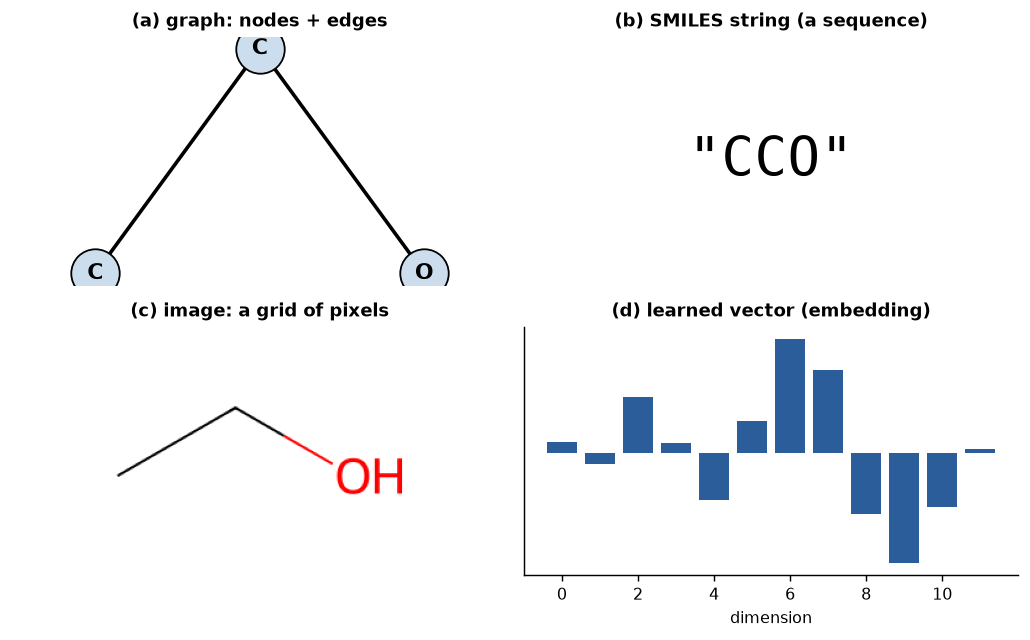

In [2]:
# One molecule (ethanol, CCO) shown as graph, string, image and a (stand-in) learned vector.
m = Chem.MolFromSmiles("CCO")
fig, ax = plt.subplots(2, 2, figsize=(8.0, 5.0))
# (a) graph: nodes and edges drawn by hand
pos = {0: (0, 0), 1: (1, 0.4), 2: (2, 0)}; lab = {0: "C", 1: "C", 2: "O"}
for i, j in [(0, 1), (1, 2)]:
    ax[0, 0].plot([pos[i][0], pos[j][0]], [pos[i][1], pos[j][1]], "k-", lw=2, zorder=1)
for i, (x, y) in pos.items():
    ax[0, 0].scatter([x], [y], s=720, c="#cde", edgecolors="k", zorder=2)
    ax[0, 0].text(x, y, lab[i], ha="center", va="center", fontsize=12, fontweight="bold")
ax[0, 0].set_title("(a) graph: nodes + edges"); ax[0, 0].axis("off"); ax[0, 0].set_xlim(-0.5, 2.5)
# (b) SMILES string
ax[0, 1].text(0.5, 0.5, '"CCO"', ha="center", va="center", fontsize=30, family="monospace")
ax[0, 1].set_title("(b) SMILES string (a sequence)"); ax[0, 1].axis("off")
# (c) image: the rendered depiction
ax[1, 0].imshow(np.array(Draw.MolToImage(m, size=(260, 200)))); ax[1, 0].axis("off")
ax[1, 0].set_title("(c) image: a grid of pixels")
# (d) learned vector: a stand-in embedding (random here; Section 4 computes a real one)
vec = rng.normal(size=12)
ax[1, 1].bar(range(12), vec, color="#2b5d9b"); ax[1, 1].set_title("(d) learned vector (embedding)")
ax[1, 1].set_xlabel("dimension"); ax[1, 1].set_yticks([])
fig.tight_layout()

<p class="caption"><b>Figure 1.</b> The same molecule, ethanol, in the four representations deep learning uses. (a) The labelled graph — the object chemistry actually defines, and the input to graph neural networks. (b) The SMILES string — a sequence, the input to language-style models. (c) The 2-D depiction as pixels — the input to image networks. (d) A fixed-length learned vector, the <em>output</em> of a network just before its prediction head; the bars here are a random stand-in, and Section 4 computes a real one. The rest of the unit concentrates on (a) and (b), because they preserve the molecule exactly and are where the field has converged.<sup class="c"><a href="#r17">[17]</a></sup></p>

<div class="box bridge"><h4>Why "learn the representation" at all?</h4>
<p>In Units 5 and 12-13 you chose a fingerprint or a set of descriptors and fed it to a random forest. That works well and is still the baseline to beat. Deep learning's bet is different: instead of fixing the molecule-to-vector map and learning only the final regressor, let the <em>whole map</em> — from atoms to the final number — be learned jointly from the labelled data, so the features adapt to the task. When there are enough labelled molecules, task-adapted features can beat generic ones; when there are few, the generic fingerprint usually wins. Section 7 makes that trade-off explicit, and reviews of the field document it across many datasets.<sup class="c"><a href="#r18">[18]</a>,<a href="#r28">[28]</a></sup></p></div>

## 2. The molecular graph and its atom features

A graph neural network needs two things from each molecule: a <strong>feature matrix</strong> $X$ with one row per atom, and the <strong>adjacency</strong> that says which atoms are bonded. The adjacency you met in Unit 1 as a 0/1 matrix; the feature matrix is new here, and choosing its columns is the one piece of chemistry you must get right before any learning happens. Each atom's row is a short vector describing the atom locally: its element (as a one-hot code, exactly like a categorical feature in ordinary machine learning), its degree, its formal charge, whether it is aromatic, and how many hydrogens it carries. These are the same atom properties you walked through for caffeine in Unit 1; now we stack them into a matrix.

The cell below builds a readable feature table for acetamide, CH₃-C(=O)-NH₂ — a four-heavy-atom molecule we will reuse for the hand-traced example in Section 3.

In [3]:
# Atom feature table for acetamide (CC(=O)N): one row per heavy atom.
aceta = Chem.MolFromSmiles("CC(=O)N")
rows = []
for a in aceta.GetAtoms():
    rows.append((a.GetIdx(), a.GetSymbol(), a.GetDegree(), a.GetTotalNumHs(),
                 a.GetFormalCharge(), int(a.GetIsAromatic())))
feat = pd.DataFrame(rows, columns=["idx", "element", "degree", "num_H", "charge", "aromatic"])
print("acetamide: %d heavy atoms, %d bonds" % (aceta.GetNumAtoms(), aceta.GetNumBonds()))
print(feat.to_string(index=False))

acetamide: 4 heavy atoms, 3 bonds
 idx element  degree  num_H  charge  aromatic
   0       C       1      3       0         0
   1       C       3      0       0         0
   2       O       1      0       0         0
   3       N       1      2       0         0


The table is the node-feature matrix in human-readable form: atom 0 is the methyl carbon (degree 1, three hydrogens), atom 1 the carbonyl carbon (degree 3, no hydrogens), atom 2 the carbonyl oxygen, atom 3 the amide nitrogen. In a real GNN each categorical column is expanded to a one-hot block, so the element column alone becomes several binary columns; Section 4 uses a compact element-only one-hot to keep the arithmetic traceable. The adjacency pairs with this table to complete the input.

degrees (row sums of A): [1, 3, 1, 1] | atom 1 is bonded to [0, 2, 3]


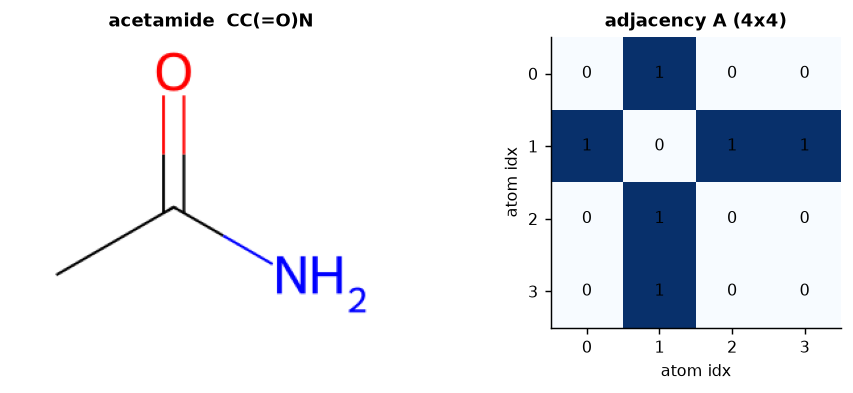

In [4]:
# The adjacency matrix of acetamide, and the molecule it describes.
A = Chem.GetAdjacencyMatrix(aceta)
fig, ax = plt.subplots(1, 2, figsize=(7.4, 3.1), gridspec_kw={"width_ratios": [1, 1.1]})
ax[0].imshow(np.array(Draw.MolToImage(aceta, size=(300, 220)))); ax[0].axis("off")
ax[0].set_title("acetamide  CC(=O)N")
im = ax[1].imshow(A, cmap="Blues")
ax[1].set_title("adjacency A (4x4)"); ax[1].set_xlabel("atom idx"); ax[1].set_ylabel("atom idx")
ax[1].set_xticks(range(4)); ax[1].set_yticks(range(4))
for (i, j), v in np.ndenumerate(A):
    ax[1].text(j, i, v, ha="center", va="center", color="k", fontsize=9)
print("degrees (row sums of A):", A.sum(1).tolist(), "| atom 1 is bonded to", A[1].nonzero()[0].tolist())
fig.tight_layout()

<p class="caption"><b>Figure 2.</b> Acetamide and its 4&times;4 adjacency matrix. The carbonyl carbon (atom 1) is the hub — row 1 has three ones, matching its degree 3 — while the methyl carbon, the oxygen and the nitrogen are each bonded only to it. This small, symmetric, low-degree matrix is the entire connectivity a GNN sees; together with the atom-feature table above it is the molecule, as far as the network is concerned. Everything in the next section operates on exactly these two objects.</p>

## 3. Message passing: the core operation of a graph neural network

Here is the central idea, and it is simpler than its reputation. A graph neural network represents each atom by a vector — its <strong>state</strong> or <strong>embedding</strong> — initialised from the atom's features. It then repeats one operation several times: every atom collects the states of its bonded neighbours (the "messages"), combines them into a summary, and uses that summary to update its own state. After one round, each atom's state reflects itself and its immediate neighbours; after two rounds, it reflects atoms two bonds away; and so on. This is <strong>message passing</strong>, and almost every molecular GNN is a special case of it.<sup class="c"><a href="#r3">[3]</a></sup>

Formally, write $h_v^{(t)}$ for the state of atom $v$ after round $t$, with $h_v^{(0)}$ the atom's input features. One round is

<div class="eq">$$h_v^{(t+1)} \;=\; \text{UPDATE}\Big(h_v^{(t)},\; \underset{u \,\in\, \mathcal{N}(v)}{\text{AGGREGATE}}\; \text{MESSAGE}\big(h_u^{(t)}\big)\Big)$$
<span class="where">$\mathcal{N}(v)$ is the set of atoms bonded to $v$. MESSAGE transforms a neighbour's state, AGGREGATE pools the neighbour messages into one vector (a sum or mean, which must not depend on neighbour order), and UPDATE folds that pooled message back into $v$'s own state. Different GNNs are different choices of these three functions.<sup class="c"><a href="#r3">[3]</a>,<a href="#r4">[4]</a></sup></span></div>

The simplest possible choice — MESSAGE is the identity, AGGREGATE is a sum, and UPDATE just adds the pooled message to the atom's own state — is already enough to see the mechanism. In matrix form that one round is $H^{(t+1)} = (A + I)\,H^{(t)}$: multiplying the stacked states by the adjacency-plus-identity sends every atom the sum of its neighbours' states and keeps its own. We will trace exactly this by hand and then run it.

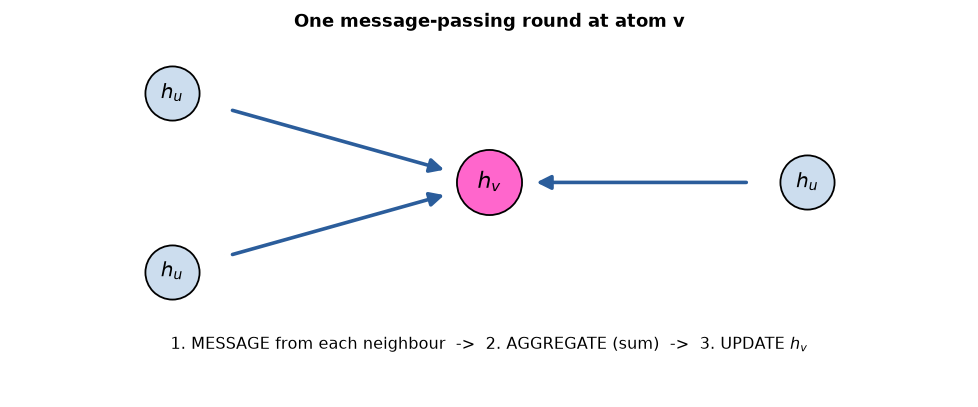

In [5]:
# Conceptual schematic of ONE message-passing round at a central atom (drawn, not computed).
fig, ax = plt.subplots(figsize=(7.6, 3.2))
ctr = (0, 0); nbr = [(-1.6, 0.8), (-1.6, -0.8), (1.6, 0.0)]
for (x, y) in nbr:
    ax.annotate("", xy=(ctr[0], ctr[1]), xytext=(x*0.82, y*0.82),
                arrowprops=dict(arrowstyle="-|>", color="#2b5d9b", lw=2, shrinkB=26, mutation_scale=16))
    ax.scatter([x], [y], s=900, c="#cde", edgecolors="k", zorder=3)
    ax.text(x, y, "$h_u$", ha="center", va="center", fontsize=11)
ax.scatter([ctr[0]], [ctr[1]], s=1300, c="#f6c", edgecolors="k", zorder=3)
ax.text(ctr[0], ctr[1], "$h_v$", ha="center", va="center", fontsize=12, fontweight="bold")
ax.text(0, -1.5, "1. MESSAGE from each neighbour  ->  2. AGGREGATE (sum)  ->  3. UPDATE $h_v$",
        ha="center", fontsize=9)
ax.set_title("One message-passing round at atom v"); ax.axis("off")
ax.set_xlim(-2.4, 2.4); ax.set_ylim(-1.9, 1.3)
fig.tight_layout()

<p class="caption"><b>Figure 3.</b> One message-passing round, schematically, at a central atom $v$ (pink) with three neighbours $u$ (blue). Each neighbour sends its current state as a message; the messages are summed (an order-independent aggregation, which is essential because a molecule's atoms have no canonical order); and the sum updates $v$'s state. Stacking several such rounds lets information flow further across the molecule, as the next cells show.</p>

### 3.1 One update, traced by hand

Let us do the arithmetic of a single round on acetamide, $\text{CC(=O)N}$, with the identity-message/sum-aggregate/add-update rule $h_v^{(1)} = h_v^{(0)} + \sum_{u \in \mathcal{N}(v)} h_u^{(0)}$. To keep it to pencil arithmetic we use a <em>scalar</em> initial state per atom: its atomic number. So $h^{(0)} = [\,6,\,6,\,8,\,7\,]$ for atoms $[\text{C}_0,\,\text{C}_1,\,\text{O}_2,\,\text{N}_3]$. The bonds are $0\!-\!1$, $1\!-\!2$, $1\!-\!3$, so atom 1 (the carbonyl carbon) is the only atom with three neighbours. Applying the rule atom by atom:

- Atom 0 (methyl C): neighbours $\{1\}$, so $h_0^{(1)} = 6 + 6 = \mathbf{12}$.
- Atom 1 (carbonyl C): neighbours $\{0, 2, 3\}$, so $h_1^{(1)} = 6 + (6 + 8 + 7) = \mathbf{27}$.
- Atom 2 (O): neighbours $\{1\}$, so $h_2^{(1)} = 8 + 6 = \mathbf{14}$.
- Atom 3 (N): neighbours $\{1\}$, so $h_3^{(1)} = 7 + 6 = \mathbf{13}$.

So by hand $h^{(1)} = [\,12,\,27,\,14,\,13\,]$. Equivalently, $h^{(1)} = (A + I)\,h^{(0)}$. The cell below builds $A$, adds the identity, and checks that the matrix product reproduces our four numbers exactly.

initial  h0 = [6, 6, 8, 7]
by code  h1 = [12, 27, 14, 13]
by hand  h1 = [12, 27, 14, 13]  ->  match: True


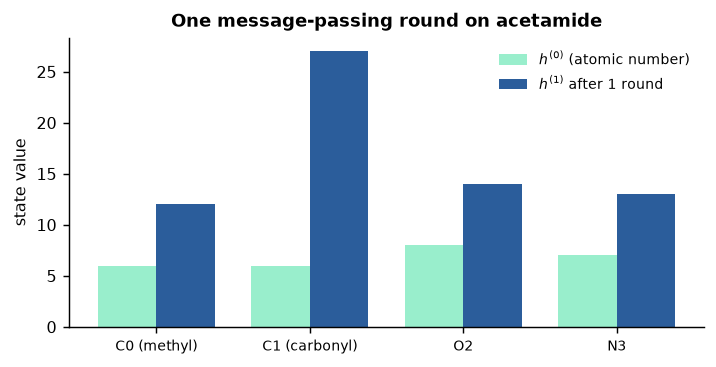

In [6]:
# Confirm the hand-traced message-passing update:  h1 = (A + I) h0.
A = Chem.GetAdjacencyMatrix(aceta).astype(int)       # 4x4, atoms C0 C1 O2 N3
h0 = np.array([a.GetAtomicNum() for a in aceta.GetAtoms()])   # [6, 6, 8, 7]
h1 = (A + np.eye(4, dtype=int)) @ h0
print("initial  h0 =", h0.tolist())
print("by code  h1 =", h1.tolist())
print("by hand  h1 = [12, 27, 14, 13]  ->  match:", h1.tolist() == [12, 27, 14, 13])
fig, ax = plt.subplots(figsize=(5.6, 2.9))
x = np.arange(4); w = 0.38; names = ["C0 (methyl)", "C1 (carbonyl)", "O2", "N3"]
ax.bar(x - w/2, h0, w, label="$h^{(0)}$ (atomic number)", color="#9ec")
ax.bar(x + w/2, h1, w, label="$h^{(1)}$ after 1 round", color="#2b5d9b")
ax.set_xticks(x); ax.set_xticklabels(names, fontsize=8); ax.set_ylabel("state value")
ax.set_title("One message-passing round on acetamide"); ax.legend(fontsize=8, frameon=False)
fig.tight_layout()

<p class="caption"><b>Figure 4.</b> The hand-traced round made visual. Before the round (light bars) every atom carries only its own atomic number. After one round (dark bars) the carbonyl carbon C1 has jumped to 27 because it summed its three neighbours, while the leaf atoms rose only modestly. The code's <code>h1</code> equals the hand-computed <code>[12, 27, 14, 13]</code> exactly — the point of a hand trace is that you can now reproduce a GNN's inner loop on paper. Real GNNs replace the scalar by a vector and the plain sum by a learned linear map followed by a nonlinearity, but the skeleton is this cell.</p>

<div class="box warn"><h4>Why sum, and not something order-dependent?</h4>
<p>A molecule's atoms have no natural numbering — the same acetamide could be written with its atoms in any order (Unit 3's canonicalisation exists precisely because of this). So the aggregation over neighbours <em>must</em> give the same answer whatever order the neighbours come in: sum, mean and max all qualify; concatenation or "first neighbour minus second" do not. This <em>permutation invariance</em> is the single hard constraint on a molecular GNN, and it is why the matrix form uses the symmetric adjacency $A$.</p></div>

### 3.2 Rounds, receptive field, and the link to Morgan/ECFP

Each extra round lets an atom's state depend on atoms one bond further away. The set of atoms that can influence a given atom's state after $t$ rounds is its <strong>receptive field</strong> — the $t$-hop neighbourhood — and it is read straight off the sparsity pattern of $(A+I)^t$. The cell below tracks, for caffeine, how many atoms each atom "sees" as the number of rounds grows.

mean receptive-field size by round: [np.float64(1.0), np.float64(3.1), np.float64(6.4), np.float64(10.0), np.float64(12.7), np.float64(13.9)]


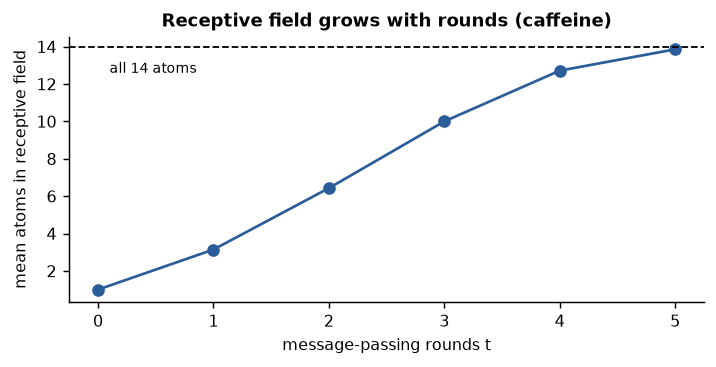

In [7]:
# Receptive field growth: how many atoms influence each atom's state after t rounds.
caf = Chem.MolFromSmiles("Cn1cnc2c1c(=O)n(C)c(=O)n2C")
Ac = Chem.GetAdjacencyMatrix(caf).astype(float) + np.eye(caf.GetNumAtoms())
reach = []
P = np.eye(caf.GetNumAtoms())
for t in range(6):
    reach.append((P > 0).sum(1).mean())      # mean number of atoms reachable within t hops
    P = P @ Ac
fig, ax = plt.subplots(figsize=(5.6, 2.9))
ax.plot(range(6), reach, "o-", color="#2b5d9b")
ax.axhline(caf.GetNumAtoms(), ls="--", color="k", lw=1)
ax.text(0.1, caf.GetNumAtoms() - 1.4, "all %d atoms" % caf.GetNumAtoms(), fontsize=8)
ax.set_xlabel("message-passing rounds t"); ax.set_ylabel("mean atoms in receptive field")
ax.set_title("Receptive field grows with rounds (caffeine)")
print("mean receptive-field size by round:", [round(r, 1) for r in reach])
fig.tight_layout()

<p class="caption"><b>Figure 5.</b> For caffeine (14 heavy atoms), the average number of atoms that can influence a given atom's state climbs with each round and saturates once the whole molecule is within reach. This is why GNNs use only a handful of rounds — typically three to five: after that, every atom already "sees" most of the molecule, and more rounds mainly blur the states together (a failure mode called over-smoothing). The number of rounds is to a GNN what the radius is to an ECFP fingerprint.</p>

<div class="box bridge"><h4>Chemistry/informatics box — you have already met message passing</h4>
<p>The Morgan algorithm of 1965<sup class="c"><a href="#r11">[11]</a></sup> assigned each atom an integer, then repeatedly replaced it by a hash of its own value and its neighbours' values — iterating until the labels stabilised, to get a canonical atom numbering. The extended-connectivity fingerprint (ECFP/Morgan fingerprint) of Unit 5<sup class="c"><a href="#r10">[10]</a></sup> does the same and records the hashed atom-environment at each radius as set bits. That <em>is</em> message passing with a hash as the UPDATE and no learning. A GNN replaces the fixed hash with a learned, differentiable function — which is exactly why GNNs are often described as "learnable ECFP". The theory confirms the analogy: the expressive power of standard message passing is bounded by the Weisfeiler-Lehman graph-isomorphism test, the same colour-refinement idea behind Morgan.<sup class="c"><a href="#r5">[5]</a></sup></p></div>

In [8]:
# Weisfeiler-Lehman / Morgan-style refinement (radius 1) distinguishes two isomers that
# composition alone cannot: ethanol (CCO) vs dimethyl ether (COC), both C2H6O.
def env_radius1(smiles):
    mol = Chem.MolFromSmiles(smiles)
    out = []
    for a in mol.GetAtoms():
        nbrs = sorted(n.GetSymbol() for n in a.GetNeighbors())
        out.append(a.GetSymbol() + "(" + ",".join(nbrs) + ")")
    return sorted(out)

for name, smi in [("ethanol   ", "CCO"), ("dimethyl ether", "COC")]:
    print("%s  %-14s atom environments: %s" % (name, smi, env_radius1(smi)))
print("same formula C2H6O, same atom counts -> only the 1-hop environments tell them apart")

ethanol     CCO            atom environments: ['C(C)', 'C(C,O)', 'O(C)']
dimethyl ether  COC            atom environments: ['C(O)', 'C(O)', 'O(C,C)']
same formula C2H6O, same atom counts -> only the 1-hop environments tell them apart


Both molecules have formula C₂H₆O and identical atom counts, so any representation that sees only <em>composition</em> cannot tell them apart — yet one is a drinkable alcohol and the other a gas. The radius-1 atom environments differ (ethanol has a carbon bonded to another carbon and nothing else; dimethyl ether's carbons are each bonded only to oxygen), so even one round of message passing separates them. This is the concrete reason structure-aware representations exist, and the next section turns it into a working model.

## 4. A minimal MPNN in NumPy that learns a graph property

We now assemble the pieces into a complete — if deliberately tiny — message-passing neural network and let it <em>learn</em> something, with no deep-learning framework. A full GNN learns the MESSAGE and UPDATE functions by back-propagation; here we fix those to the simplest sum rule of Section 3 and learn only the final <strong>read-out</strong> — the linear map from the pooled molecule vector to the prediction. That is honest about what is learned (the read-out weights, fit by least squares) and what is fixed (the aggregation), and it still demonstrates the key claim: a structure-aware embedding solves a task that atom composition alone cannot.

The task is to predict a molecule's <strong>number of bonds</strong> from its atoms. This looks trivial, but it is exactly the kind of property that composition cannot pin down: for an acyclic (ring-free) molecule the number of bonds equals the number of heavy atoms minus one, so counting atoms suffices; but every <em>ring</em> adds a bond without adding an atom, so a molecule's ring count is invisible to composition and visible only to something that looks at connectivity. Message passing sees connectivity through atom degrees, so it should recover the bond count exactly where composition fails. First we build a small, varied dataset of real molecules — some acyclic, some with rings.

In [9]:
# A small, varied dataset of real small molecules: a mix of acyclic and ring-containing.
smiles = [
    "CCO","CCCO","CCCCO","CC(C)O","CCN","CCCN","CC(=O)O","CCC(=O)O","CC(=O)N","CCOC(C)=O",
    "CCOCC","CCCCCC","CC(C)CC(=O)O","OCC(O)CO","NCCO","CSC","CCS","CC#N","CCCl","ClCCCl",
    "CC(=O)OC","CCCCN","O=CO","CCCC(=O)O","CN(C)C",
    "c1ccccc1","Cc1ccccc1","c1ccncc1","Oc1ccccc1","Nc1ccccc1",
    "CC(=O)Oc1ccccc1C(=O)O","Cn1cnc2c1c(=O)n(C)c(=O)n2C","C1CCCCC1","C1CCCC1","O=C1CCCCC1",
    "c1ccc2ccccc2c1","C1CCNCC1","c1ccoc1","c1cc[nH]c1","c1ccsc1",
    "CC(C)Cc1ccc(C(C)C(=O)O)cc1","O=C(O)c1ccccc1O","c1ccc(-c2ccccc2)cc1","C1CC1","O1CCOCC1",
]
mols = [Chem.MolFromSmiles(s) for s in smiles]
y = np.array([m.GetNumBonds() for m in mols], dtype=float)          # target: number of bonds
has_ring = np.array([m.GetRingInfo().NumRings() > 0 for m in mols])
print("molecules:", len(mols), "| with >=1 ring:", int(has_ring.sum()),
      "| acyclic:", int((~has_ring).sum()))
print("bond-count target: min %d, max %d, mean %.1f" % (y.min(), y.max(), y.mean()))

molecules: 45 | with >=1 ring: 20 | acyclic: 25
bond-count target: min 2, max 15, mean 5.4


The dataset has both ring-free and ring-containing molecules, so the bond count genuinely varies in a way composition cannot explain. Now the model. We featurise each atom by a one-hot of its element, run $T$ rounds of the sum update, and pool (sum) the atom states after <em>each</em> round into one long vector — concatenating the per-round pools, exactly the trick of Duvenaud's neural fingerprints,<sup class="c"><a href="#r2">[2]</a></sup> which keeps information from every radius. That pooled vector is the molecule's learned embedding; a linear read-out maps it to the prediction.

In [10]:
# Element one-hot node features and the sum-update graph embedding (concatenate per-round pools).
ELEMS = ["C", "N", "O", "F", "S", "Cl"]
def node_features(mol):
    X = np.zeros((mol.GetNumAtoms(), len(ELEMS) + 1))      # +1 = "other element" bucket
    for a in mol.GetAtoms():
        s = a.GetSymbol()
        X[a.GetIdx(), ELEMS.index(s) if s in ELEMS else len(ELEMS)] = 1.0
    return X

def graph_embedding(mol, T):
    X = node_features(mol)
    Ahat = Chem.GetAdjacencyMatrix(mol).astype(float) + np.eye(mol.GetNumAtoms())
    h, pools = X, [X.sum(0)]                               # pool after 0 rounds = composition
    for _ in range(T):
        h = Ahat @ h                                      # one message-passing round
        pools.append(h.sum(0))                            # pool this round's states
    return np.concatenate(pools)

emb_demo = graph_embedding(Chem.MolFromSmiles("c1ccccc1"), T=2)
print("benzene embedding (T=2) has length", emb_demo.size, "= 7 features x (T+1) pools")
print("first 7 entries (= atom composition pool):", emb_demo[:7].astype(int).tolist())

benzene embedding (T=2) has length 21 = 7 features x (T+1) pools
first 7 entries (= atom composition pool): [6, 0, 0, 0, 0, 0, 0]


The embedding for benzene at $T=2$ has length 21 — the seven element features pooled after 0, 1 and 2 rounds — and its first seven entries are just the atom composition (six carbons, in the C column). The later blocks carry the neighbourhood information. Now we fit the linear read-out by least squares for $T=0$ (composition only), $T=1$ and $T=2$, on a train/test split, and read off the test error.

In [11]:
# Fit a linear read-out on the graph embedding by least squares; compare T = 0, 1, 2.
perm = rng.permutation(len(mols)); cut = int(0.7 * len(mols))
tr, te = perm[:cut], perm[cut:]
def fit_eval(T):
    Phi = np.array([np.append(graph_embedding(m, T), 1.0) for m in mols])   # +bias column
    w, *_ = np.linalg.lstsq(Phi[tr], y[tr], rcond=None)
    pred = Phi @ w
    mae_tr = np.abs(pred[tr] - y[tr]).mean(); mae_te = np.abs(pred[te] - y[te]).mean()
    return pred, mae_tr, mae_te
results = {T: fit_eval(T) for T in (0, 1, 2)}
for T in (0, 1, 2):
    _, mtr, mte = results[T]
    print("T=%d rounds | train MAE %.3f | test MAE %.3f bonds" % (T, mtr, mte))

T=0 rounds | train MAE 0.320 | test MAE 0.305 bonds
T=1 rounds | train MAE 0.000 | test MAE 0.000 bonds
T=2 rounds | train MAE 0.000 | test MAE 0.019 bonds


The printout tells the whole story: with $T=0$ (composition only) the model is off by a sizeable fraction of a bond on the held-out molecules, and the error is concentrated on the ring-containing ones it cannot explain; adding even one round of message passing collapses the test error to essentially zero, because the pooled degrees give the model $2\times$ the number of bonds directly (the handshake lemma: the degrees of all atoms sum to twice the number of edges). The figure makes the failure and the fix visible.

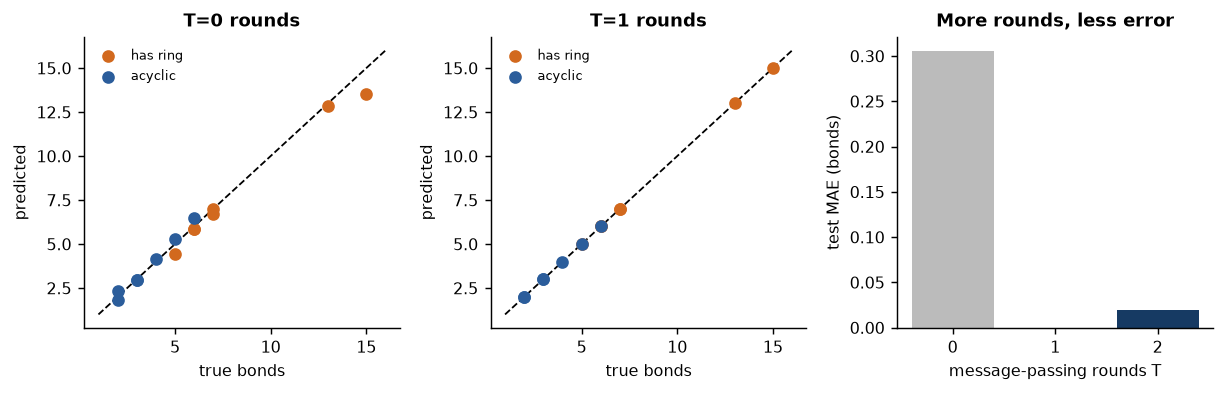

In [12]:
# Visualise: predicted vs true bonds for T=0 and T=1, and test MAE by number of rounds.
fig, ax = plt.subplots(1, 3, figsize=(9.4, 3.1))
for k, T in enumerate((0, 1)):
    pred, _, _ = results[T]
    ax[k].scatter(y[te][has_ring[te]], pred[te][has_ring[te]], c="#d2691e", label="has ring", zorder=3)
    ax[k].scatter(y[te][~has_ring[te]], pred[te][~has_ring[te]], c="#2b5d9b", label="acyclic", zorder=3)
    lo, hi = y.min() - 1, y.max() + 1
    ax[k].plot([lo, hi], [lo, hi], "k--", lw=1)
    ax[k].set_title("T=%d rounds" % T); ax[k].set_xlabel("true bonds"); ax[k].set_ylabel("predicted")
    ax[k].legend(fontsize=7, frameon=False)
maes = [results[T][2] for T in (0, 1, 2)]
ax[2].bar([0, 1, 2], maes, color=["#bbb", "#2b5d9b", "#163a63"])
ax[2].set_xticks([0, 1, 2]); ax[2].set_xlabel("message-passing rounds T")
ax[2].set_ylabel("test MAE (bonds)"); ax[2].set_title("More rounds, less error")
fig.tight_layout()

<p class="caption"><b>Figure 6.</b> The structure-aware embedding solving a task composition cannot. Left ($T=0$, composition only): the acyclic molecules (blue) sit on the diagonal — their bond count is atoms minus one — but the ring-containing molecules (orange) fall below it, because the model cannot see the extra ring-closure bonds. Middle ($T=1$): one round of message passing puts every molecule on the diagonal. Right: test error drops to near zero once the first round is added and stays there. This is the clearest small example of <em>why</em> deep learning on graphs exists — the learned-read-out model recovers a property that no amount of atom counting could.<sup class="c"><a href="#r6">[6]</a>,<a href="#r7">[7]</a></sup></p>

<div class="box warn"><h4>What this demo does and does not show</h4>
<p>It shows that a structure-aware embedding beats composition on a structural property, with a <em>learned</em> (fitted) read-out. It does <em>not</em> train the message function — that stays fixed as a sum — so it is not a full GNN; a real MPNN learns the MESSAGE/UPDATE weights by back-propagation, which needs a framework (Section 8). Treat this as the skeleton you could hang learnable weights on, not as a competitive model.</p></div>

## 5. Learned versus fixed fingerprints

Section 4's pooled embedding is a <strong>fingerprint</strong> in the Unit-5 sense — a fixed-length vector summarising the whole molecule — but with a crucial difference. The ECFP/Morgan fingerprint of Unit 5 is <em>fixed</em>: a rule hashes each atom environment into a predetermined bit, and no part of it adapts to your task.<sup class="c"><a href="#r10">[10]</a></sup> A neural fingerprint is <em>learned</em>: the functions that turn atom environments into vector entries are differentiable and are trained end-to-end with the predictor, so the representation bends toward whatever property you are predicting.<sup class="c"><a href="#r2">[2]</a></sup> The two sit at opposite ends of a spectrum, and the table below contrasts them directly.

In [13]:
# Fixed (Morgan/ECFP) vs learned-style (our pooled embedding) fingerprints, side by side.
from rdkit.Chem import rdFingerprintGenerator
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
compare = pd.DataFrame({
    "property": ["adapts to the task?", "needs labelled data?", "typical length",
                 "each entry means", "differentiable?"],
    "fixed ECFP (Unit 5)": ["no, rule-based", "no", "1024-2048 bits",
                            "a specific atom environment", "no"],
    "learned (neural FP)": ["yes, trained end-to-end", "yes", "tens-hundreds floats",
                            "a learned combination", "yes"],
})
print(compare.to_string(index=False))
bench = Chem.MolFromSmiles("CC(=O)Oc1ccccc1C(=O)O")        # aspirin
on_bits = list(gen.GetFingerprint(bench).GetOnBits())
print("\naspirin ECFP: %d of 2048 bits set (sparse, binary)" % len(on_bits))
print("aspirin neural-style embedding (T=2): length %d, dense floats"
      % graph_embedding(bench, 2).size)

            property         fixed ECFP (Unit 5)     learned (neural FP)
 adapts to the task?              no, rule-based yes, trained end-to-end
needs labelled data?                          no                     yes
      typical length              1024-2048 bits    tens-hundreds floats
    each entry means a specific atom environment   a learned combination
     differentiable?                          no                     yes

aspirin ECFP: 24 of 2048 bits set (sparse, binary)
aspirin neural-style embedding (T=2): length 21, dense floats


The contrast is concrete: aspirin's ECFP is a long, sparse, binary vector where each set bit names a specific substructure you can look up (interpretable but frozen), while the neural-style embedding is short and dense, with entries that mean whatever training made them mean (adaptable but opaque). Neither is universally better. The figure visualises the difference across a handful of molecules.

ECFP density: 0.8% of shown bits set; embedding is fully dense


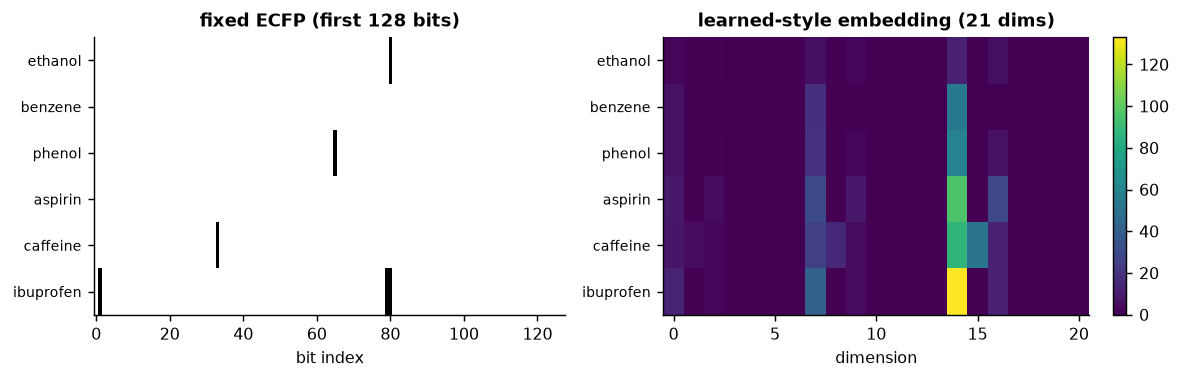

In [14]:
# Visual contrast: ECFP bit patterns vs dense learned-style embeddings for six molecules.
names = ["ethanol", "benzene", "phenol", "aspirin", "caffeine", "ibuprofen"]
sm = ["CCO", "c1ccccc1", "Oc1ccccc1", "CC(=O)Oc1ccccc1C(=O)O",
      "Cn1cnc2c1c(=O)n(C)c(=O)n2C", "CC(C)Cc1ccc(C(C)C(=O)O)cc1"]
ms = [Chem.MolFromSmiles(s) for s in sm]
ecfp = np.array([list(gen.GetFingerprint(m)) for m in ms])[:, :128]       # first 128 bits for display
emb = np.array([graph_embedding(m, 2) for m in ms])
fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.0))
ax[0].imshow(ecfp, aspect="auto", cmap="Greys", interpolation="nearest")
ax[0].set_title("fixed ECFP (first 128 bits)"); ax[0].set_xlabel("bit index")
ax[0].set_yticks(range(6)); ax[0].set_yticklabels(names, fontsize=8)
im = ax[1].imshow(emb, aspect="auto", cmap="viridis")
ax[1].set_title("learned-style embedding (21 dims)"); ax[1].set_xlabel("dimension")
ax[1].set_yticks(range(6)); ax[1].set_yticklabels(names, fontsize=8)
fig.colorbar(im, ax=ax[1], fraction=0.046); fig.tight_layout()
print("ECFP density: %.1f%% of shown bits set; embedding is fully dense" % (100 * ecfp.mean()))

<p class="caption"><b>Figure 7.</b> Two fingerprint philosophies. Left: the ECFP bit matrix is almost empty — only about one percent of the shown bits are set — and each black square is a specific substructure present in that molecule; this sparsity and interpretability are why fixed fingerprints remain the default for similarity search and small-data modelling (Units 5, 11). Right: the learned-style embedding is dense and low-dimensional, every entry contributing to every molecule; its entries are not individually meaningful but the vector as a whole can be tuned to a task. Learned fingerprints shine when you have enough labels to train them and a task where generic substructure bits miss the signal.<sup class="c"><a href="#r19">[19]</a></sup></p>

## 6. Sequence models: SMILES as a language

The second great family of molecular deep-learning models drops the graph and treats the molecule as <em>text</em>. A SMILES string (Unit 3)<sup class="c"><a href="#r12">[12]</a></sup> is a sequence of characters, so the same networks that model natural language — recurrent networks such as the LSTM,<sup class="c"><a href="#r14">[14]</a></sup> and today transformers<sup class="c"><a href="#r15">[15]</a></sup> — can model molecules. A SMILES language model learns the probability of the next character given the characters so far; once trained, sampling characters one at a time generates new strings, which is the basis of the generative models of Unit 18.<sup class="c"><a href="#r13">[13]</a></sup>

To make the mechanism tangible without a framework, we build the simplest possible sequence model: a <strong>character-level Markov model</strong>. It estimates, from a corpus of SMILES, the probability of each character given only the single preceding character (a bigram model). That is a one-step memory — far weaker than an LSTM or transformer — but it already shows how generation works and why it is hard. We first assemble the vocabulary and the bigram counts.

In [15]:
# Build a character-level bigram model over a SMILES corpus. '^' = start, '$' = end.
corpus = smiles + ["CCOCCO", "CC(C)(C)O", "c1ccc(Cl)cc1", "CC(N)C(=O)O", "OC(=O)CCC(=O)O",
                   "c1ccc(C=O)cc1", "CCOC(=O)c1ccccc1", "CNc1ccccc1", "CC(=O)Nc1ccccc1O"]
texts = ["^" + s + "$" for s in corpus]
vocab = sorted(set("".join(texts)))
idx = {c: i for i, c in enumerate(vocab)}
V = len(vocab)
counts = np.ones((V, V))                      # add-one (Laplace) smoothing
for t in texts:
    for a, b in zip(t[:-1], t[1:]):
        counts[idx[a], idx[b]] += 1
P = counts / counts.sum(1, keepdims=True)     # row-normalised transition probabilities
print("corpus size:", len(texts), "SMILES | vocabulary:", V, "characters")
print("characters:", "".join(vocab))
print("P('C' -> next) top 3:", sorted(zip(P[idx["C"]], vocab), reverse=True)[:3])

corpus size: 54 SMILES | vocabulary: 21 characters
characters: #$()-12=CHNOS[]^clnos
P('C' -> next) top 3: [(np.float64(0.4024390243902439), 'C'), (np.float64(0.14634146341463414), '('), (np.float64(0.07926829268292683), 'O')]


The vocabulary is the set of characters that appear in the corpus — atoms (C, c, N, O, ...), bond and branch symbols (=, #, (, )), ring digits, and our start/end markers. The transition matrix $P$ holds the probability of each next character given the current one; after a carbon, the most likely next characters are another carbon, a branch, or a ring-closure digit, which matches chemical intuition. The matrix is the whole model, and it is worth seeing.

row for '^' (start) favours: [(np.float64(0.49333333333333335), 'C'), (np.float64(0.13333333333333333), 'c'), (np.float64(0.10666666666666667), 'O')]


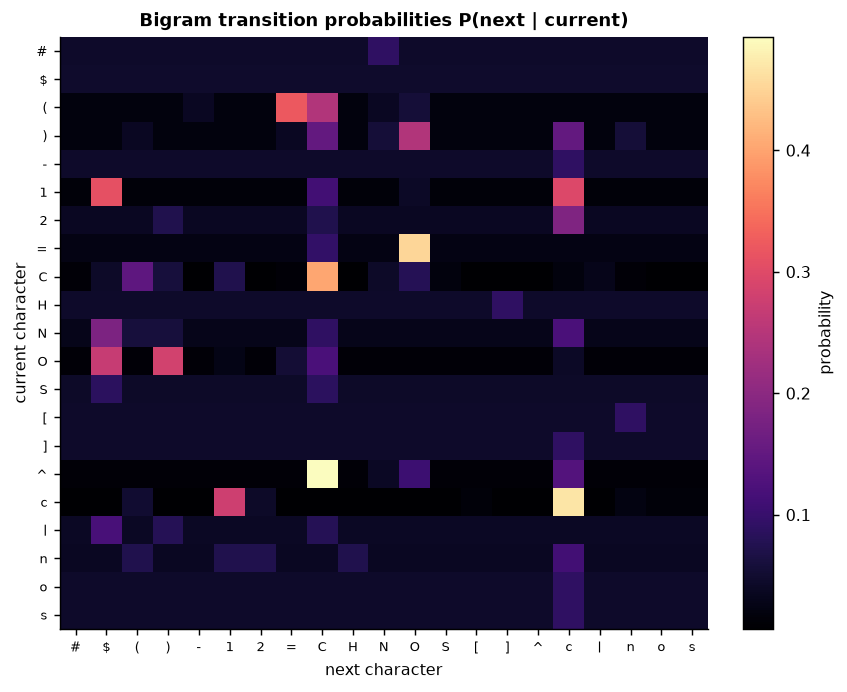

In [16]:
# The bigram transition matrix as a heatmap: structure is visible in the character grammar.
fig, ax = plt.subplots(figsize=(6.6, 5.4))
im = ax.imshow(P, cmap="magma", aspect="auto")
ax.set_xticks(range(V)); ax.set_xticklabels(vocab, fontsize=7)
ax.set_yticks(range(V)); ax.set_yticklabels(vocab, fontsize=7)
ax.set_xlabel("next character"); ax.set_ylabel("current character")
ax.set_title("Bigram transition probabilities P(next | current)")
fig.colorbar(im, ax=ax, fraction=0.046, label="probability"); fig.tight_layout()
print("row for '^' (start) favours:", sorted(zip(P[idx['^']], vocab), reverse=True)[:3])

<p class="caption"><b>Figure 8.</b> The bigram model as a heatmap. Bright cells are likely character transitions: the start marker '^' leads most often into 'C', 'c' or 'O' (molecules usually begin with a common atom), lowercase aromatic letters follow one another (aromatic rings are runs of 'c'), and digits follow atoms (ring-closure labels). The grid is the grammar the model has learned from one-character context — enough to capture local habits of SMILES, but, as we see next, nowhere near enough to respect the long-range rules (matched parentheses, paired ring digits) that make a string a <em>valid</em> molecule.</p>

Generation is now simple: start at '^', repeatedly sample the next character from the current character's row of $P$, and stop at '$'. We generate a batch and check each string with RDKit's parser — a string is a <em>valid</em> molecule only if <code>Chem.MolFromSmiles</code> returns a molecule rather than <code>None</code>.

In [17]:
# Sample new SMILES from the bigram model and test chemical validity with RDKit.
def sample_bigram(max_len=60):
    out, cur = [], "^"
    for _ in range(max_len):
        cur = vocab[rng.choice(V, p=P[idx[cur]])]
        if cur == "$":
            break
        out.append(cur)
    return "".join(out)

N = 400
samples = [sample_bigram() for _ in range(N)]
valid = [s for s in samples if s and Chem.MolFromSmiles(s) is not None]
print("generated", N, "strings | valid molecules:", len(valid),
      "(%.1f%%)" % (100 * len(valid) / N))
print("example valid samples:", valid[:6] if valid else "(none)")
print("example invalid samples:", [s for s in samples if s and Chem.MolFromSmiles(s) is None][:4])

generated 400 strings | valid molecules: 46 (11.5%)
example valid samples: ['O', 'O=O', 'CCC', 'O=O', 'CCCO', 'S']
example invalid samples: ['c(=2Nc1', 'C(-S1c1c2(CcSoN=OsoNccccCCCc1ccn#nss)oncc1cc1N=n', 'O1', 'O)n']


A one-character memory produces mostly <em>invalid</em> strings: it happily opens a branch "(" or a ring digit and never closes it, because remembering to close requires memory of what was opened dozens of characters earlier — exactly the long-range dependency a bigram lacks. Notice that the <em>valid</em> samples it does produce are trivially short — a lone atom or a two-atom chain like those printed above — while anything ambitious breaks. The failure is therefore long-range, and it should get sharply worse for longer strings. The cell below confirms it by binning the generated strings by length and measuring how many are valid in each bin.

validity by length bin: {'1-2': 55, '3-4': 13, '5-7': 3, '8-11': 0, '12-60': 0}


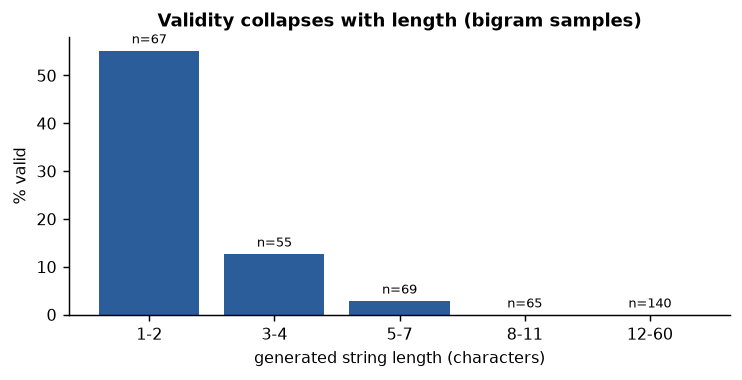

In [18]:
# The core difficulty is long-range: validity collapses as the generated string gets longer.
lengths = np.array([len(s) for s in samples])
vmask = np.array([bool(s) and Chem.MolFromSmiles(s) is not None for s in samples])
edges = [1, 3, 5, 8, 12, 61]
labels, rates, nbin = [], [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    m = (lengths >= lo) & (lengths < hi)
    if m.sum():
        labels.append("%d-%d" % (lo, hi - 1)); rates.append(100 * vmask[m].mean()); nbin.append(int(m.sum()))
fig, ax = plt.subplots(figsize=(5.8, 3.0))
bars = ax.bar(labels, rates, color="#2b5d9b")
for b, n in zip(bars, nbin):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1.5, "n=%d" % n, ha="center", fontsize=7)
ax.set_xlabel("generated string length (characters)"); ax.set_ylabel("% valid")
ax.set_title("Validity collapses with length (bigram samples)")
print("validity by length bin:", dict(zip(labels, [round(r) for r in rates])))
fig.tight_layout()

<p class="caption"><b>Figure 9.</b> Why generation is genuinely hard. Roughly half of the shortest generated strings (one or two characters — typically a lone atom) parse as valid molecules, but the valid fraction falls toward zero as soon as the strings are long enough to require matched parentheses and paired ring-closure digits — exactly the long-range structure a one- or two-character memory cannot track. A higher-order Markov model (a trigram) sharpens the local grammar but does not fix this; only models with long memory — LSTMs<sup class="c"><a href="#r14">[14]</a></sup> and today transformers — reliably generate complex <em>and</em> valid molecules, routinely exceeding nine in ten valid.<sup class="c"><a href="#r13">[13]</a></sup> This is the gap between a toy and a tool, and the reason Unit 18 builds generative design on real sequence (and graph) models, not bigrams. An alternative that sidesteps validity entirely is to generate the graph directly, or to use a string grammar (SELFIES) in which every string is valid by construction.</p>

<div class="box bridge"><h4>Chemistry box — what "valid" means here</h4>
<p>A SMILES string is <em>valid</em> if it parses into a chemically sensible molecule: every ring-opening digit has a matching closing digit, every branch parenthesis is balanced, and the implied valences are achievable (a carbon with five bonds is rejected). RDKit's <code>MolFromSmiles</code> performs exactly these checks (Unit 4's sanitisation), returning <code>None</code> on failure. Validity is necessary but not sufficient for a <em>useful</em> molecule — a valid SMILES can still describe something unstable or unsynthesisable, which is why generative pipelines pair a language model with the filters of Unit 9 and the synthetic-accessibility scoring of Unit 17.</p></div>

## 7. When is deep learning worth it?

You now have both families — graph networks and sequence models — in miniature. The practical question for a working cheminformatician is not "are they impressive?" but "should I reach for them instead of the ECFP-plus-random-forest baseline of Units 5 and 13?" The honest, evidence-based answer is: <em>sometimes</em>, and it depends mostly on how much labelled data you have and how different your task is from what generic fingerprints already capture. Three findings from the literature frame the decision.

1. <strong>Data size is the main lever.</strong> Deep models have many parameters and learn their own features, so they need many labelled examples to pay off; with a few hundred molecules, a random forest on ECFP usually matches or beats a GNN, while with tens of thousands the GNN often pulls ahead. The large MoleculeNet benchmark showed graph models winning on some large datasets and losing on small ones,<sup class="c"><a href="#r8">[8]</a></sup> and careful comparisons have repeatedly found that well-tuned descriptor/fingerprint models with gradient-boosted trees remain extremely strong baselines that GNNs do not automatically beat.<sup class="c"><a href="#r20">[20]</a></sup>
2. <strong>The task matters.</strong> When the property depends on subtle, non-local or learned-feature structure — some ADMET and toxicity endpoints, quantum-chemical properties — learned representations have a real edge, and the chemprop directed-MPNN in particular is a strong, well-engineered graph model.<sup class="c"><a href="#r7">[7]</a>,<a href="#r23">[23]</a></sup> When the property is largely additive or substructure-driven, fixed fingerprints already encode what matters and deep learning adds cost without accuracy.
3. <strong>Honest validation decides the winner, not the headline number.</strong> Everything from Unit 14 applies with extra force: random splits inflate deep models (which can memorise), so scaffold or time splits are mandatory;<sup class="c"><a href="#r24">[24]</a></sup> and both model classes degrade sharply on <em>activity cliffs</em> — pairs of near-identical molecules with very different activity — which no current representation handles well.<sup class="c"><a href="#r21">[21]</a></sup>

The schematic below summarises the data-size trade-off qualitatively; the exact crossover point depends on the dataset and task.

Illustrative curves only — the real crossover depends on task; see refs [7],[8],[20].


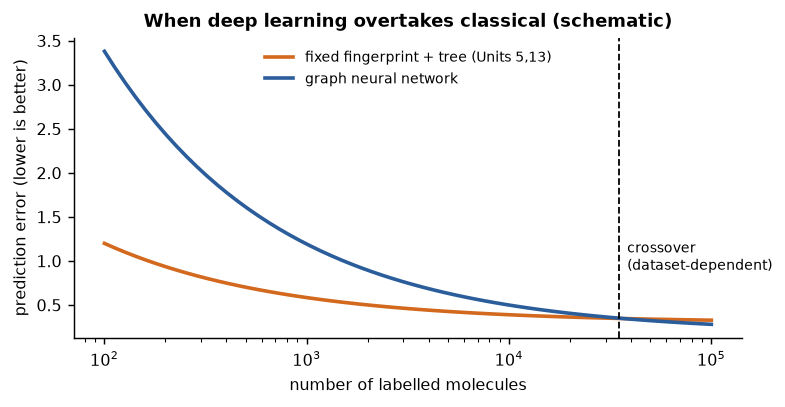

In [19]:
# Schematic (illustrative, NOT measured here): error vs dataset size for two model classes.
n = np.logspace(2, 5, 60)                       # training-set size, 100 .. 100000
err_fp = 0.30 + 0.9 / np.sqrt(n / 100)          # fingerprint + tree: strong early, flattens
err_gnn = 0.18 + 3.2 / np.sqrt(n / 100)         # GNN: worse when small, keeps improving
fig, ax = plt.subplots(figsize=(6.2, 3.2))
ax.plot(n, err_fp, color="#d2691e", lw=2, label="fixed fingerprint + tree (Units 5,13)")
ax.plot(n, err_gnn, color="#2b5d9b", lw=2, label="graph neural network")
cross = n[np.argmin(np.abs(err_fp - err_gnn))]
ax.axvline(cross, ls="--", color="k", lw=1)
ax.text(cross * 1.1, 0.9, "crossover\n(dataset-dependent)", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("number of labelled molecules")
ax.set_ylabel("prediction error (lower is better)")
ax.set_title("When deep learning overtakes classical (schematic)")
ax.legend(fontsize=8, frameon=False); fig.tight_layout()
print("Illustrative curves only — the real crossover depends on task; see refs [7],[8],[20].")

<p class="caption"><b>Figure 10.</b> The qualitative trade-off (illustrative curves, not measured in this notebook, as the printout states). With few labelled molecules the fixed-fingerprint-plus-tree baseline (orange) wins because it needs no data to build its features; as the labelled set grows, the graph network (blue) keeps improving and eventually overtakes it. The crossover is dataset- and task-dependent — sometimes a few thousand molecules, sometimes never within reach. The lesson for practice: always run the classical baseline of Units 5 and 13 first, and only adopt a deep model if it beats that baseline under the honest split of Unit 14.<sup class="c"><a href="#r20">[20]</a></sup></p>

We can at least measure one real curve on our own data: how our learned-read-out model's error falls as we give it more training molecules — a genuine learning curve, not a schematic.

test MAE by train size: [np.float64(0.15), np.float64(0.053), np.float64(0.03), np.float64(0.026), np.float64(0.006)]


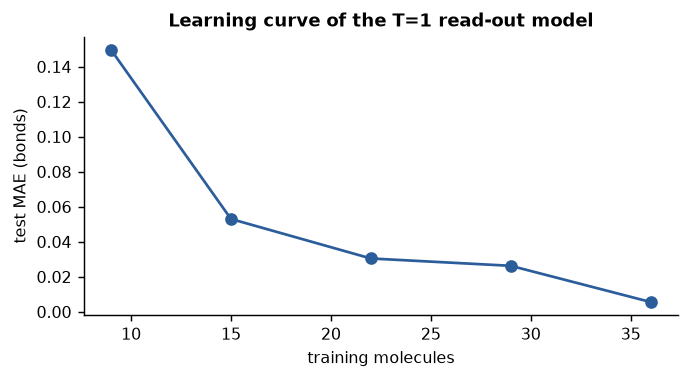

In [20]:
# A real learning curve on our data: test MAE of the T=1 model vs training-set size.
Phi1 = np.array([np.append(graph_embedding(m, 1), 1.0) for m in mols])
fracs = [0.2, 0.35, 0.5, 0.65, 0.8]
curve = []
for f in fracs:
    errs = []
    for seed in range(20):                      # average over 20 random splits
        g = np.random.default_rng(seed); p = g.permutation(len(mols))
        k = max(5, int(f * len(mols))); a, b = p[:k], p[k:]
        w, *_ = np.linalg.lstsq(Phi1[a], y[a], rcond=None)
        errs.append(np.abs(Phi1[b] @ w - y[b]).mean())
    curve.append(np.mean(errs))
fig, ax = plt.subplots(figsize=(5.4, 3.0))
ax.plot([int(f * len(mols)) for f in fracs], curve, "o-", color="#2b5d9b")
ax.set_xlabel("training molecules"); ax.set_ylabel("test MAE (bonds)")
ax.set_title("Learning curve of the T=1 read-out model")
print("test MAE by train size:", [round(c, 3) for c in curve])
fig.tight_layout()

<p class="caption"><b>Figure 11.</b> A real learning curve: even our tiny model improves as it sees more training molecules, the universal shape of supervised learning (Unit 13). The error is already small because the bond-count task is easy for a degree-aware model, but the downward trend is the same one that governs when a data-hungry deep model becomes worthwhile — more data, lower error, until the curve flattens at the model's capacity.</p>

## 8. The real tools: production models, transfer learning and uncertainty

Everything above was built to be understood, not deployed. For real work you reach for maintained libraries that implement trained, back-propagating graph and sequence models efficiently — described here, deliberately not run (they need a framework and often a GPU, outside this course's scope).

- <strong>chemprop</strong> implements the directed message-passing network of Yang et al.,<sup class="c"><a href="#r7">[7]</a></sup> which passes messages along <em>bonds</em> rather than atoms and is one of the strongest and most reproducible molecular property predictors available; it is the model behind the discovery of the antibiotic halicin, found by screening a chemprop model's predictions over a large library and then validating the top hits in the laboratory.<sup class="c"><a href="#r9">[9]</a></sup>
- <strong>DeepChem</strong> is a broad toolkit of molecular featurisers, datasets and model implementations (graph, sequence and classical), paired with the MoleculeNet benchmark<sup class="c"><a href="#r8">[8]</a></sup> for standardised comparison; the Therapeutics Data Commons extends that idea to a large collection of drug-discovery tasks with fixed splits.<sup class="c"><a href="#r26">[26]</a></sup>

Two ideas from mainstream deep learning carry over and are worth naming. <strong>Transfer learning</strong> pretrains a model on a large unlabelled or loosely labelled corpus of molecules — learning general chemical "grammar" — and then fine-tunes it on your small labelled task; molecular foundation models such as the transformer-based ChemBERTa pretrain on millions of SMILES in exactly this way.<sup class="c"><a href="#r16">[16]</a></sup> And <strong>uncertainty quantification</strong> — a model saying how sure it is — matters more in chemistry than in most domains, because predictions guide expensive experiments; ensembles and related methods give calibrated uncertainties that tell you which predictions to trust.<sup class="c"><a href="#r25">[25]</a></sup> We can demonstrate the ensemble idea honestly with our own model, by bootstrapping the read-out.

mean predictive std: 0.051 | corr(std, |error|): 0.98


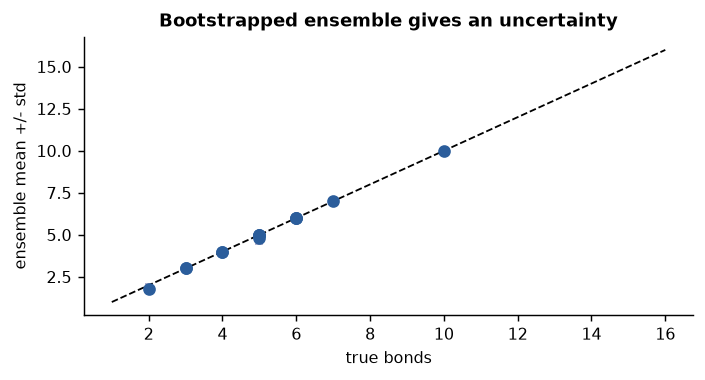

In [21]:
# Uncertainty by bootstrapping the read-out: resample the training set, refit, measure spread.
g = np.random.default_rng(1); p = g.permutation(len(mols)); cut = int(0.7 * len(mols))
trn, tst = p[:cut], p[cut:]
preds = []
for _ in range(200):                              # 200 bootstrap read-outs = a tiny ensemble
    bs = g.choice(trn, size=len(trn), replace=True)
    w, *_ = np.linalg.lstsq(Phi1[bs], y[bs], rcond=None)
    preds.append(Phi1[tst] @ w)
preds = np.array(preds)
mean, std = preds.mean(0), preds.std(0)
abs_err = np.abs(mean - y[tst])
fig, ax = plt.subplots(figsize=(5.4, 3.0))
ax.errorbar(y[tst], mean, yerr=std, fmt="o", color="#2b5d9b", ecolor="#aac", capsize=2)
lo, hi = y.min() - 1, y.max() + 1; ax.plot([lo, hi], [lo, hi], "k--", lw=1)
ax.set_xlabel("true bonds"); ax.set_ylabel("ensemble mean +/- std")
ax.set_title("Bootstrapped ensemble gives an uncertainty")
print("mean predictive std: %.3f | corr(std, |error|): %.2f"
      % (std.mean(), np.corrcoef(std, abs_err)[0, 1]))
fig.tight_layout()

<p class="caption"><b>Figure 12.</b> A bootstrapped ensemble of two hundred read-outs gives every prediction an error bar — the spread of the ensemble — at essentially no extra conceptual cost. Where the bars are wide, the models disagree and the prediction should be trusted less; a positive correlation between the predictive spread and the actual error (reported in the printout) is the minimum one wants from a usable uncertainty estimate. Production tools offer more principled methods,<sup class="c"><a href="#r25">[25]</a></sup> but the ensemble intuition is exactly this, and it is why ensembles are the default uncertainty recipe in molecular deep learning. Interpretability methods — which atoms drove a prediction — are a parallel need, now served by dedicated explainable-AI tools for molecules.<sup class="c"><a href="#r22">[22]</a></sup></p>

<div class="box bridge"><h4>Where this sits in the course and beyond</h4>
<p>This unit is the deep-learning counterpart of the classical modelling in Units 12-13 and the honest validation of Unit 14, all three sharing one discipline: a baseline, a fair split, and a measured improvement before any claim. The generative side of deep learning — turning a trained sequence or graph model around to <em>design</em> new molecules — is Unit 18. For structure-based deep learning (predicting how a molecule binds a protein, or protein structure itself) you need the bioinformatics course: those methods use 3-D protein structure, docking and dynamics, which are out of scope here by design. The free online text by White is an excellent next step for the mathematics of molecular deep learning,<sup class="c"><a href="#r27">[27]</a></sup> and the review by Keith et al. places it in the wider computational-chemistry landscape.<sup class="c"><a href="#r28">[28]</a></sup></p></div>

## 9. Summary

You should now be able to explain, without notes:

- The four representations a neural network can take of a molecule — graph, SMILES string, image, learned vector — and which network class each enables.
- That a graph neural network represents each atom by a state and updates it by <strong>message passing</strong>: MESSAGE from neighbours, order-independent AGGREGATE, UPDATE — the whole of which is $H^{(t+1)} = \text{UPDATE}(H^{(t)}, A\,\text{MESSAGE}(H^{(t)}))$, with the simplest case $(A+I)H^{(t)}$.
- How to trace one message-passing update by hand on a small molecule and reproduce it as a matrix product.
- Why more rounds grow the receptive field, why three to five rounds is typical, and how message passing generalises the Morgan/ECFP idea into a learnable form bounded by the Weisfeiler-Lehman test.
- What a learned fingerprint is and how it trades the ECFP's sparsity and interpretability for task-adaptive, dense, differentiable features.
- How a character-level SMILES model generates molecules, why a short-memory model produces mostly invalid strings, and why LSTMs/transformers fix that.
- When deep learning is worth it over fingerprints-plus-trees — chiefly a question of data size, task, and honest validation — and the production tools (chemprop, DeepChem), transfer learning and uncertainty quantification.

## 10. Self-assessment

<details><summary>1. A molecule is fed to a graph neural network. What two objects must you supply per molecule, and what does each row/entry mean?</summary>An atom-feature matrix $X$ (one row per atom, columns encoding element, degree, charge, aromaticity, hydrogen count) and the adjacency matrix $A$ (entry $A_{ij}=1$ if atoms $i$ and $j$ are bonded). $X$ gives the node labels, $A$ gives the connectivity; together they are the molecular graph the network sees.</details>

<details><summary>2. Write one message-passing round in words, and give the simplest matrix form.</summary>Each atom collects its neighbours' states (MESSAGE), pools them order-independently (AGGREGATE, e.g. a sum), and folds the pooled message into its own state (UPDATE). The simplest case — identity message, sum aggregation, additive update — is $H^{(t+1)} = (A+I)H^{(t)}$.</details>

<details><summary>3. For acetamide CC(=O)N with initial states equal to atomic numbers [6, 6, 8, 7] and the rule $h_v^{(1)} = h_v^{(0)} + \sum_{u\in\mathcal N(v)} h_u^{(0)}$, compute the carbonyl carbon's new state by hand.</summary>The carbonyl carbon (atom 1) is bonded to atoms 0, 2 and 3, so $h_1^{(1)} = 6 + (6 + 8 + 7) = 27$. The full vector is $[12, 27, 14, 13]$, matching $(A+I)h^{(0)}$.</details>

<details><summary>4. Why must the neighbour aggregation be a sum, mean or max rather than, say, concatenation?</summary>Because atoms have no canonical order, the result must be <em>permutation invariant</em>: the same molecule numbered differently must give the same states. Sum/mean/max are order-independent; concatenation or order-dependent combinations are not and would make the model depend on an arbitrary atom numbering.</details>

<details><summary>5. A GNN uses four message-passing rounds. Roughly how far across the molecule can one atom's final state "see", and why not use twenty rounds?</summary>About four bonds (its 4-hop neighbourhood — the receptive field grows one bond per round). Using many more rounds causes over-smoothing: every atom ends up seeing the whole molecule and the states blur toward one another, losing the local distinctions that carry the signal.</details>

<details><summary>6. In the Section-4 demo, why does the composition-only (T=0) model fail on ring-containing molecules but succeed on acyclic ones?</summary>For an acyclic molecule, bonds = atoms &minus; 1, so atom counts determine the bond count. A ring adds a bond without adding an atom, so composition cannot detect it; message passing exposes it through atom degrees (summed degrees = twice the number of bonds).</details>

<details><summary>7. State one advantage of a fixed ECFP fingerprint and one advantage of a learned fingerprint.</summary>ECFP: interpretable (each bit is a specific substructure) and needs no training data, so it is strong on small datasets and ideal for similarity search. Learned: adapts its features to the task and is differentiable, so it can capture task-specific signal that generic bits miss — when enough labelled data is available.</details>

<details><summary>8. Why does a character-level bigram SMILES model generate so many invalid molecules?</summary>Validity requires long-range consistency — balanced parentheses and paired ring-closure digits — but a bigram remembers only the single previous character, so it cannot recall what it opened earlier. Models with long memory (LSTM, transformer) respect these dependencies and generate mostly valid strings.</details>

<details><summary>9. You have 300 labelled molecules for a new assay. Should you start with a GNN or with ECFP + random forest, and why?</summary>Start with ECFP + random forest (Units 5, 13). With a few hundred molecules the data-hungry GNN rarely beats a well-tuned fingerprint baseline; adopt a deep model only if it outperforms that baseline under a scaffold or time split (Unit 14).</details>

<details><summary>10. What does chemprop do differently from the plain atom-based MPNN of this unit, and what is one famous result it enabled?</summary>chemprop passes messages along <em>directed bonds</em> rather than atoms (a directed MPNN) and learns the message/update functions by back-propagation. It enabled the machine-learning discovery of the antibiotic halicin by ranking a large compound library and validating top predictions experimentally.</details>

<details><summary>11. How does bootstrapping a read-out give an uncertainty estimate, and what property should that estimate have?</summary>Resample the training set with replacement many times, refit the read-out each time, and take the spread (standard deviation) of the resulting predictions as the uncertainty. A useful estimate is <em>calibrated</em>: predictions with larger spread should on average have larger actual error.</details>

<details><summary>12. Why is message passing described as a "learnable Morgan/ECFP algorithm"?</summary>Both iteratively update each atom from its own value and its neighbours' values. Morgan/ECFP uses a fixed hash as the update and records set bits; a GNN replaces the hash with a learned, differentiable function. Their expressive power is even bounded by the same Weisfeiler-Lehman colour-refinement test.</details>

## Glossary

<dl class="gloss">
<dt>Message passing</dt><dd>The core GNN operation: each atom updates its state from its own state and an order-independent summary of its neighbours' states, repeated for several rounds.</dd>
<dt>Graph neural network (GNN)</dt><dd>A neural network that operates on a graph by message passing, producing atom and whole-molecule representations.</dd>
<dt>MPNN</dt><dd>Message-passing neural network — the unifying framework (MESSAGE/AGGREGATE/UPDATE) that most molecular GNNs are special cases of.</dd>
<dt>Atom state / embedding</dt><dd>The vector a GNN keeps for each atom, initialised from atom features and updated each round.</dd>
<dt>Receptive field</dt><dd>The set of atoms that can influence a given atom's state after $t$ rounds — its $t$-hop neighbourhood.</dd>
<dt>Aggregation (permutation-invariant)</dt><dd>Pooling neighbour messages with an order-independent function (sum, mean, max), required because atoms have no canonical order.</dd>
<dt>Read-out / pooling</dt><dd>Combining all atom states into one fixed-length vector for the whole molecule, then mapping it to a prediction.</dd>
<dt>Learned fingerprint</dt><dd>A molecule vector produced by a trained network, adapted to the task — contrasted with the fixed, rule-based ECFP of Unit 5.</dd>
<dt>ECFP / Morgan fingerprint</dt><dd>A fixed fingerprint that hashes each atom's radial environment into bits (Unit 5); the non-learned ancestor of message passing.</dd>
<dt>Weisfeiler-Lehman test</dt><dd>A graph-isomorphism colour-refinement procedure; it bounds the expressive power of standard message passing.</dd>
<dt>SMILES language model</dt><dd>A sequence model that predicts the next character of a SMILES string; sampling it generates new molecules.</dd>
<dt>Validity (generated SMILES)</dt><dd>Whether a generated string parses into a chemically sensible molecule (balanced rings/branches, achievable valences).</dd>
<dt>Transfer learning</dt><dd>Pretraining on a large (often unlabelled) corpus, then fine-tuning on a small labelled task.</dd>
<dt>Uncertainty quantification</dt><dd>Estimating how confident a model is in each prediction, e.g. by the spread of an ensemble.</dd>
<dt>Over-smoothing</dt><dd>The blurring of atom states toward one another when too many message-passing rounds are used.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">LeCun Y, Bengio Y, Hinton G. Deep learning. <em>Nature</em>. 2015;521:436-444. <a href="https://doi.org/10.1038/nature14539">doi:10.1038/nature14539</a></li>
<li id="r2">Duvenaud D, Maclaurin D, Aguilera-Iparraguirre J, et al. Convolutional networks on graphs for learning molecular fingerprints. <em>Adv Neural Inf Process Syst (NeurIPS)</em>. 2015. <a href="https://doi.org/10.48550/arXiv.1509.09292">doi:10.48550/arXiv.1509.09292</a></li>
<li id="r3">Gilmer J, Schoenholz SS, Riley PF, Vinyals O, Dahl GE. Neural message passing for quantum chemistry. <em>Proc Int Conf Mach Learn (ICML)</em>. 2017. <a href="https://doi.org/10.48550/arXiv.1704.01212">doi:10.48550/arXiv.1704.01212</a></li>
<li id="r4">Kipf TN, Welling M. Semi-supervised classification with graph convolutional networks. <em>Int Conf Learn Represent (ICLR)</em>. 2017. <a href="https://doi.org/10.48550/arXiv.1609.02907">doi:10.48550/arXiv.1609.02907</a></li>
<li id="r5">Xu K, Hu W, Leskovec J, Jegelka S. How powerful are graph neural networks? <em>Int Conf Learn Represent (ICLR)</em>. 2019. <a href="https://doi.org/10.48550/arXiv.1810.00826">doi:10.48550/arXiv.1810.00826</a></li>
<li id="r6">Kearnes S, McCloskey K, Berndl M, Pande V, Riley P. Molecular graph convolutions: moving beyond fingerprints. <em>J Comput Aided Mol Des</em>. 2016;30(8):595-608. <a href="https://doi.org/10.1007/s10822-016-9938-8">doi:10.1007/s10822-016-9938-8</a></li>
<li id="r7">Yang K, Swanson K, Jin W, et al. Analyzing learned molecular representations for property prediction. <em>J Chem Inf Model</em>. 2019;59(8):3370-3388. <a href="https://doi.org/10.1021/acs.jcim.9b00237">doi:10.1021/acs.jcim.9b00237</a></li>
<li id="r8">Wu Z, Ramsundar B, Feinberg EN, et al. MoleculeNet: a benchmark for molecular machine learning. <em>Chem Sci</em>. 2018;9:513-530. <a href="https://doi.org/10.1039/C7SC02664A">doi:10.1039/C7SC02664A</a></li>
<li id="r9">Stokes JM, Yang K, Swanson K, et al. A deep learning approach to antibiotic discovery. <em>Cell</em>. 2020;180(4):688-702. <a href="https://doi.org/10.1016/j.cell.2020.01.021">doi:10.1016/j.cell.2020.01.021</a></li>
<li id="r10">Rogers D, Hahn M. Extended-connectivity fingerprints. <em>J Chem Inf Model</em>. 2010;50(5):742-754. <a href="https://doi.org/10.1021/ci100050t">doi:10.1021/ci100050t</a></li>
<li id="r11">Morgan HL. The generation of a unique machine description for chemical structures. <em>J Chem Doc</em>. 1965;5(2):107-113. <a href="https://doi.org/10.1021/c160017a018">doi:10.1021/c160017a018</a></li>
<li id="r12">Weininger D. SMILES, a chemical language and information system. 1. Introduction to methodology and encoding rules. <em>J Chem Inf Comput Sci</em>. 1988;28(1):31-36. <a href="https://doi.org/10.1021/ci00057a005">doi:10.1021/ci00057a005</a></li>
<li id="r13">Segler MHS, Kogej T, Tyrchan C, Waller MP. Generating focused molecule libraries for drug discovery with recurrent neural networks. <em>ACS Cent Sci</em>. 2018;4(1):120-131. <a href="https://doi.org/10.1021/acscentsci.7b00512">doi:10.1021/acscentsci.7b00512</a></li>
<li id="r14">Hochreiter S, Schmidhuber J. Long short-term memory. <em>Neural Comput</em>. 1997;9(8):1735-1780. <a href="https://doi.org/10.1162/neco.1997.9.8.1735">doi:10.1162/neco.1997.9.8.1735</a></li>
<li id="r15">Vaswani A, Shazeer N, Parmar N, et al. Attention is all you need. <em>Adv Neural Inf Process Syst (NeurIPS)</em>. 2017. <a href="https://doi.org/10.48550/arXiv.1706.03762">doi:10.48550/arXiv.1706.03762</a></li>
<li id="r16">Chithrananda S, Grand G, Ramsundar B. ChemBERTa: large-scale self-supervised pretraining for molecular property prediction. <em>arXiv</em>. 2020. <a href="https://doi.org/10.48550/arXiv.2010.09885">doi:10.48550/arXiv.2010.09885</a></li>
<li id="r17">Wieder O, Kohlbacher S, Kuenemann M, et al. A compact review of molecular property prediction with graph neural networks. <em>Drug Discov Today Technol</em>. 2020;37:1-12. <a href="https://doi.org/10.1016/j.ddtec.2020.11.009">doi:10.1016/j.ddtec.2020.11.009</a></li>
<li id="r18">Walters WP, Barzilay R. Applications of deep learning in molecule generation and molecular property prediction. <em>Acc Chem Res</em>. 2021;54(2):263-270. <a href="https://doi.org/10.1021/acs.accounts.0c00699">doi:10.1021/acs.accounts.0c00699</a></li>
<li id="r19">Chuang KV, Gunsalus LM, Keiser MJ. Learning molecular representations for medicinal chemistry. <em>J Med Chem</em>. 2020;63(16):8705-8722. <a href="https://doi.org/10.1021/acs.jmedchem.0c00385">doi:10.1021/acs.jmedchem.0c00385</a></li>
<li id="r20">Jiang D, Wu Z, Hsieh C-Y, et al. Could graph neural networks learn better molecular representation for drug discovery? A comparison study of descriptor-based and graph-based models. <em>J Cheminform</em>. 2021;13:12. <a href="https://doi.org/10.1186/s13321-020-00479-8">doi:10.1186/s13321-020-00479-8</a></li>
<li id="r21">van Tilborg D, Alenicheva A, Grisoni F. Exposing the limitations of molecular machine learning with activity cliffs. <em>J Chem Inf Model</em>. 2022;62(23):5938-5951. <a href="https://doi.org/10.1021/acs.jcim.2c01073">doi:10.1021/acs.jcim.2c01073</a></li>
<li id="r22">Jiménez-Luna J, Grisoni F, Schneider G. Drug discovery with explainable artificial intelligence. <em>Nat Mach Intell</em>. 2020;2:573-584. <a href="https://doi.org/10.1038/s42256-020-00236-4">doi:10.1038/s42256-020-00236-4</a></li>
<li id="r23">Mayr A, Klambauer G, Unterthiner T, Hochreiter S. DeepTox: toxicity prediction using deep learning. <em>Front Environ Sci</em>. 2016;3:80. <a href="https://doi.org/10.3389/fenvs.2015.00080">doi:10.3389/fenvs.2015.00080</a></li>
<li id="r24">Sheridan RP. Time-split cross-validation as a method for estimating the goodness of prospective prediction. <em>J Chem Inf Model</em>. 2013;53(4):783-790. <a href="https://doi.org/10.1021/ci400084k">doi:10.1021/ci400084k</a></li>
<li id="r25">Scalia G, Grambow CA, Pernici B, Li Y-P, Green WH. Evaluating scalable uncertainty estimation methods for deep learning-based molecular property prediction. <em>J Chem Inf Model</em>. 2020;60(6):2697-2717. <a href="https://doi.org/10.1021/acs.jcim.9b00975">doi:10.1021/acs.jcim.9b00975</a></li>
<li id="r26">Huang K, Fu T, Gao W, et al. Artificial intelligence foundation for therapeutic science. <em>Nat Chem Biol</em>. 2022;18:1033-1036. <a href="https://doi.org/10.1038/s41589-022-01131-2">doi:10.1038/s41589-022-01131-2</a></li>
<li id="r27">White AD. Deep learning for molecules and materials. <em>Living J Comput Mol Sci</em>. 2022;3(1):1499. <a href="https://doi.org/10.33011/livecoms.3.1.1499">doi:10.33011/livecoms.3.1.1499</a></li>
<li id="r28">Keith JA, Vassilev-Galindo V, Cheng B, et al. Combining machine learning and computational chemistry for predictive insights into chemical systems. <em>Chem Rev</em>. 2021;121(16):9816-9872. <a href="https://doi.org/10.1021/acs.chemrev.1c00107">doi:10.1021/acs.chemrev.1c00107</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>Goodfellow I, Bengio Y, Courville A. <em>Deep Learning</em>. MIT Press; 2016. — The standard reference for the neural-network machinery used here (free online).</li>
<li>Leach AR, Gillet VJ. <em>An Introduction to Chemoinformatics</em>. Springer; 2007. — Fingerprints and molecular representations at a chemist's depth.</li>
<li>Bajorath J (ed.). <em>Chemoinformatics for Drug Discovery</em>. Wiley; 2014. — Applications-oriented chapters on molecular ML.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>White AD. <em>Deep Learning for Molecules and Materials</em> — <a href="https://dmol.pub/">dmol.pub</a>. The best free, code-first companion to this unit.</li>
<li>chemprop documentation and repository — <a href="https://chemprop.readthedocs.io/">chemprop.readthedocs.io</a>.</li>
<li>DeepChem tutorials and MoleculeNet — <a href="https://deepchem.io/">deepchem.io</a>.</li>
<li>Therapeutics Data Commons — <a href="https://tdcommons.ai/">tdcommons.ai</a>.</li>
<li>TeachOpenCADD talktorials on GNNs and molecular ML — <a href="https://projects.volkamerlab.org/teachopencadd/">projects.volkamerlab.org/teachopencadd</a>.</li>
</ul>